# streamTrack: `method='pspline'` vs `method='binned'`

galpy PRs #1731 (feat/backends) and #1732 (main) add a second way to
reconstruct the mean track and its covariance from spray particles and make
it the default. The two methods differ in how particles are assigned to the
progenitor's orbit and how the track is fit:

| | `binned` (previous default) | `pspline` (new default) |
|---|---|---|
| assignment | closest of ~10⁴ discrete orbit samples (argmin) | continuous projection onto the orbit (Newton) |
| fit | means in `tp` bins, then GCV smoothing splines | weighted cubic penalized spline fit to the particles |
| smoothing | GCV per spline | REML per phase-space coordinate |
| range trim, auto velocity weight | order statistics (sorted quantiles) | smoothed quantiles |

Every step of `binned` is piecewise constant in the particles: a small change
in the progenitor moves some particles to a different orbit sample or bin, and
the track jumps. `pspline` is a smooth function of the particles, so the track
is a smooth function of the progenitor's parameters — what a gradient-based fit
(or a finite-difference derivative) needs. This notebook shows that, and that
both methods estimate the same track.

Setup: the Bovy (2014) stream in a flattened logarithmic halo (as in
`stream_track_examples.ipynb`), leading arm, N = 1000 particles.

In [1]:
import time

import numpy
from matplotlib import pyplot
from astropy import units as u

from galpy.df import fardal15spraydf
from galpy.orbit import Orbit
from galpy.potential import LogarithmicHaloPotential

%matplotlib inline

lp = LogarithmicHaloPotential(normalize=1.0, q=0.9)
ro, vo = 8.0, 220.0
vxvv0 = numpy.array([1.56148083, 0.35081535, -1.15481504, 0.88719443,
                     -0.47713334, 0.12019596])
T = Orbit(vxvv0, ro=ro, vo=vo).align_to_orbit()
N = 1000
TP0 = 0.7  # where along the leading arm we read off the track (internal time)


def make_spdf(dvT=0.0):
    """Spray DF with the progenitor's vT offset by dvT km/s"""
    vxvv = vxvv0.copy()
    vxvv[2] += dvT / vo
    return fardal15spraydf(progenitor_mass=2e4 * u.Msun,
                           progenitor=Orbit(vxvv, ro=ro, vo=vo), pot=lp,
                           tdisrupt=4.5 * u.Gyr, tail="leading")


def both_tracks(dvT=0.0, seed=1, n=N):
    """Both reconstructions of one particle sample. The same seed gives the
    same random draws for every dvT (common random numbers), so the particles
    are a smooth function of dvT and only the reconstruction can jump."""
    spdf = make_spdf(dvT)
    numpy.random.seed(seed)
    ps = spdf.streamTrack(n=n, tail="leading", custom_sky_transform=T)
    bn = spdf.streamTrack(particles=ps.particles, tail="leading",
                          custom_sky_transform=T, method="binned")
    return ps, bn


ps0, bn0 = both_tracks()
print("leading-arm tp range: pspline", ps0.tp_grid()[[0, -1]],
      " binned", bn0.tp_grid()[[0, -1]])

leading-arm tp range: pspline [0.         1.46808135]  binned [0.         1.45085526]


## 1. Same particles, two reconstructions

The tracks agree to a fraction of the stream's width (bottom panel: the
difference in units of the track's cross-stream dispersion σ_φ2).

max |binned - pspline| in phi2: 0.052 deg = 0.32 sigma_phi2 (median sigma_phi2 = 0.223 deg)


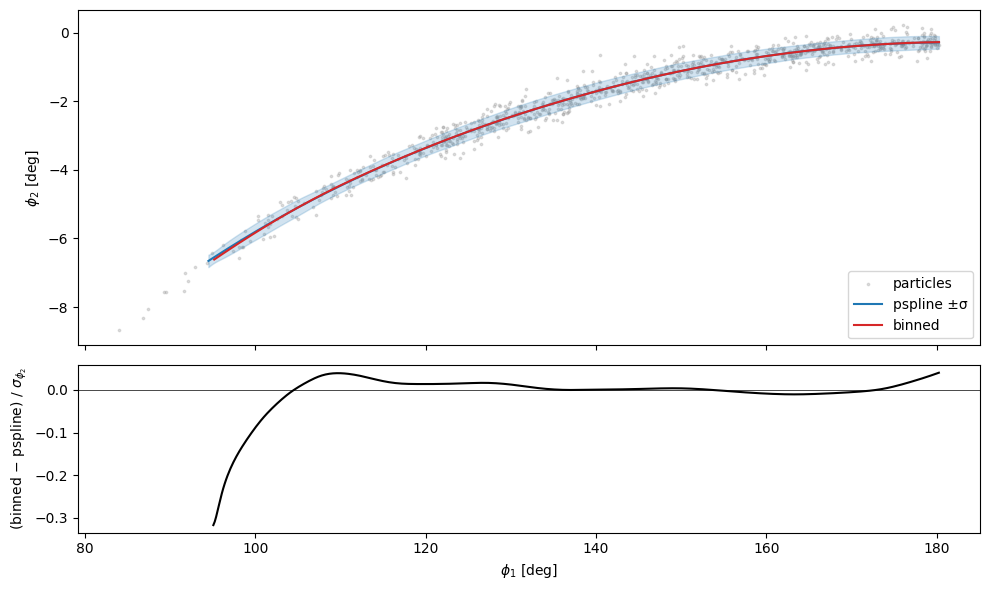

In [2]:
xv = ps0.particles
o = Orbit(xv.T, ro=ro, vo=vo)
p1_s, p2_s = o.phi1(T=T), o.phi2(T=T)

lo = max(ps0.tp_grid().min(), bn0.tp_grid().min())
hi = min(ps0.tp_grid().max(), bn0.tp_grid().max())
tps = numpy.linspace(lo, hi, 301)
sig = numpy.sqrt([ps0.cov(t, basis="customsky")[1, 1] for t in tps])

fig, axes = pyplot.subplots(2, 1, figsize=(10, 6), sharex=True,
                            gridspec_kw={"height_ratios": [2, 1]})
ax = axes[0]; pyplot.sca(ax)
ax.scatter(p1_s, p2_s, s=3, alpha=0.3, color="0.6", label="particles")
ps0.plot(d1="phi1", d2="phi2", spread=1, color="C0", label="pspline ±σ")
bn0.plot(d1="phi1", d2="phi2", color="C3", label="binned")
ax.set_ylabel(r"$\phi_2$ [deg]"); ax.legend(loc="lower right")
ax = axes[1]
dphi2 = bn0.phi2(tps) - ps0.phi2(tps)
ax.plot(ps0.phi1(tps), dphi2 / sig, "k-")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel(r"$\phi_1$ [deg]")
ax.set_ylabel(r"(binned $-$ pspline) / $\sigma_{\phi_2}$")
fig.tight_layout()
print(f"max |binned - pspline| in phi2: {numpy.max(numpy.abs(dphi2)):.3f} deg "
      f"= {numpy.max(numpy.abs(dphi2) / sig):.2f} sigma_phi2 "
      f"(median sigma_phi2 = {numpy.median(sig):.3f} deg)")

## 2. The track as a function of a progenitor parameter

Offset the progenitor's tangential velocity by δv_T and read off the track's
φ₂ at a fixed point along the leading arm (`tp = TP0`). The particles are
drawn with the same random numbers for every δv_T, so they move smoothly; any
jump comes from the reconstruction.

41 samples in 118 s
pspline: rms residual from a quadratic = 3.52e-06 deg
binned: rms residual from a quadratic = 3.24e-03 deg


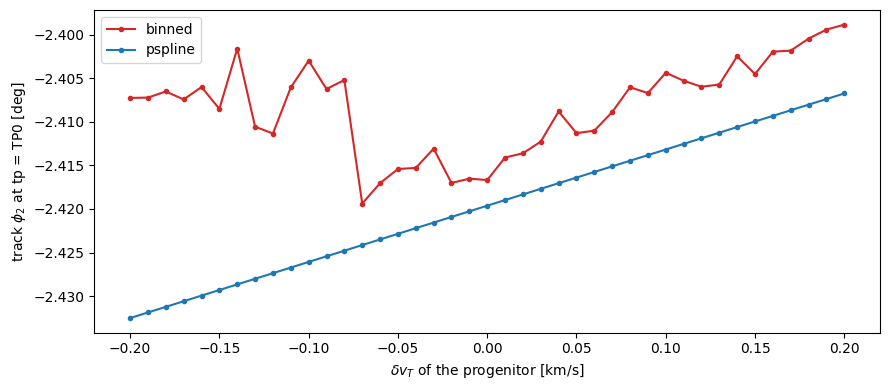

In [3]:
dvTs = numpy.linspace(-0.2, 0.2, 41)  # km/s
t0 = time.perf_counter()
q_ps, q_bn = [], []
for d in dvTs:
    ps, bn = both_tracks(d)
    q_ps.append(float(ps.phi2(TP0)))
    q_bn.append(float(bn.phi2(TP0)))
q_ps, q_bn = numpy.array(q_ps), numpy.array(q_bn)
print(f"{len(dvTs)} samples in {time.perf_counter() - t0:.0f} s")

fig, ax = pyplot.subplots(figsize=(9, 4))
ax.plot(dvTs, q_bn, "o-", color="C3", ms=3, label="binned")
ax.plot(dvTs, q_ps, "o-", color="C0", ms=3, label="pspline")
ax.set_xlabel(r"$\delta v_T$ of the progenitor [km/s]")
ax.set_ylabel(r"track $\phi_2$ at tp = TP0 [deg]")
ax.legend()
fig.tight_layout()

# Roughness: residual from a quadratic fit
for name, q in (("pspline", q_ps), ("binned", q_bn)):
    res = q - numpy.polyval(numpy.polyfit(dvTs, q, 2), dvTs)
    print(f"{name}: rms residual from a quadratic = {numpy.std(res):.2e} deg")

## 3. Finite-difference derivatives

Central differences of the same quantity at δv_T = 0 for decreasing steps.
A smooth function converges as the step shrinks; a piecewise-constant one
gives zero or a step's height divided by the step.

   step [km/s]    pspline [deg/(km/s)]    binned [deg/(km/s)]
       1e-01              0.064443             -0.006969
       3e-02              0.064473              0.013397
       1e-02              0.064476              0.120973
       3e-03              0.064477              0.168204
       1e-03              0.064477              1.264242
       1e-04              0.064477              0.724219
       1e-05              0.064477             -0.166471


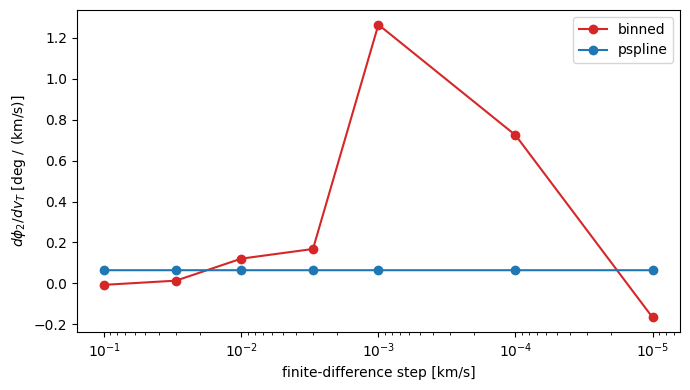

In [4]:
hs = numpy.array([1e-1, 3e-2, 1e-2, 3e-3, 1e-3, 1e-4, 1e-5])  # km/s
d_ps, d_bn = [], []
for h in hs:
    psp, bnp = both_tracks(h)
    psm, bnm = both_tracks(-h)
    d_ps.append((float(psp.phi2(TP0)) - float(psm.phi2(TP0))) / (2 * h))
    d_bn.append((float(bnp.phi2(TP0)) - float(bnm.phi2(TP0))) / (2 * h))
d_ps, d_bn = numpy.array(d_ps), numpy.array(d_bn)
print("   step [km/s]    pspline [deg/(km/s)]    binned [deg/(km/s)]")
for h, a, b in zip(hs, d_ps, d_bn):
    print(f"   {h:9.0e}      {a:16.6f}      {b:16.6f}")

fig, ax = pyplot.subplots(figsize=(7, 4))
ax.semilogx(hs, d_bn, "o-", color="C3", label="binned")
ax.semilogx(hs, d_ps, "o-", color="C0", label="pspline")
ax.invert_xaxis()
ax.set_xlabel("finite-difference step [km/s]")
ax.set_ylabel(r"$d\phi_2/d v_T$ [deg / (km/s)]")
ax.legend()
fig.tight_layout()

## 4. Seed-to-seed scatter

Both reconstructions of 16 independent samples at δv_T = 0: the two methods
estimate the same track (their mean difference is within the noise), and the
penalized spline is less noisy.

In [5]:
seeds = numpy.arange(16)
s_ps, s_bn = [], []
for s in seeds:
    ps, bn = both_tracks(0.0, seed=s)
    s_ps.append(float(ps.phi2(TP0)))
    s_bn.append(float(bn.phi2(TP0)))
s_ps, s_bn = numpy.array(s_ps), numpy.array(s_bn)
diff = s_bn - s_ps
print(f"phi2 at TP0 over {len(seeds)} seeds:")
print(f"  pspline: mean {s_ps.mean():.3f}, scatter {s_ps.std(ddof=1):.3f} deg")
print(f"  binned:  mean {s_bn.mean():.3f}, scatter {s_bn.std(ddof=1):.3f} deg")
print(f"  binned - pspline: {diff.mean():+.3f} +- {diff.std(ddof=1) / numpy.sqrt(len(seeds)):.3f} deg")

phi2 at TP0 over 16 seeds:
  pspline: mean -2.407, scatter 0.014 deg
  binned:  mean -2.403, scatter 0.014 deg
  binned - pspline: +0.005 +- 0.003 deg


## 5. Speed and memory

Fit time and peak memory (numpy allocations, via `tracemalloc`) on a fixed
particle sample. Sampling the particles, the orbit integrations, is the same
for both methods and not included. The binned fit's closest-point search
compares every particle with every orbit sample, so its memory grows as
N × 10⁴.

In [6]:
import tracemalloc

spdf = make_spdf()
for n in (1000, 10000):
    numpy.random.seed(3)
    xv = spdf.streamTrack(n=n, tail="leading", custom_sky_transform=T).particles
    for method in ("pspline", "binned"):
        t0 = time.perf_counter()
        spdf.streamTrack(particles=xv, tail="leading", custom_sky_transform=T,
                         method=method)
        dt = time.perf_counter() - t0
        tracemalloc.start()
        spdf.streamTrack(particles=xv, tail="leading", custom_sky_transform=T,
                         method=method)
        peak = tracemalloc.get_traced_memory()[1]
        tracemalloc.stop()
        print(f"N = {n:6d}  {method:8s} fit: {dt:6.2f} s, peak memory {peak / 1e9:5.2f} GB")

N =   1000  pspline  fit:   0.05 s, peak memory  0.01 GB


N =   1000  binned   fit:   0.59 s, peak memory  0.08 GB


N =  10000  pspline  fit:   0.34 s, peak memory  0.07 GB


N =  10000  binned   fit:   1.87 s, peak memory  0.81 GB


## Summary

- On the same particles the two reconstructions agree to a fraction of the
  stream's width (0.05° = 0.3 σ_φ2 at most here), and over 16 independent
  samples they estimate the same track (difference 0.005 ± 0.003°, against a
  seed-to-seed scatter of 0.014° for either method).
- As a function of the progenitor's v_T, the `pspline` track is smooth
  (3.5e-6° rms about a quadratic over ±0.2 km/s) while the `binned` track
  jumps (3.2e-3° rms). Finite-difference derivatives of the `pspline` track
  converge (0.064477 deg/(km/s) for every step from 1e-2 to 1e-5 km/s); those
  of the `binned` track range from −0.17 to +1.26 depending on the step.
- The `pspline` fit is about 5–10× faster and needs about a tenth of the
  memory (N = 10⁴: 0.34 s and 0.07 GB, against 1.9 s and 0.81 GB).